In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path("../data")
TRAIN_DIR = DATA_DIR / "Training"
TEST_DIR = DATA_DIR / "Testing"

Aantal klassen: 62
Totaal afbeeldingen: 4575
Kleinste klasse: 00026 6
Grootste klasse: 00022 375


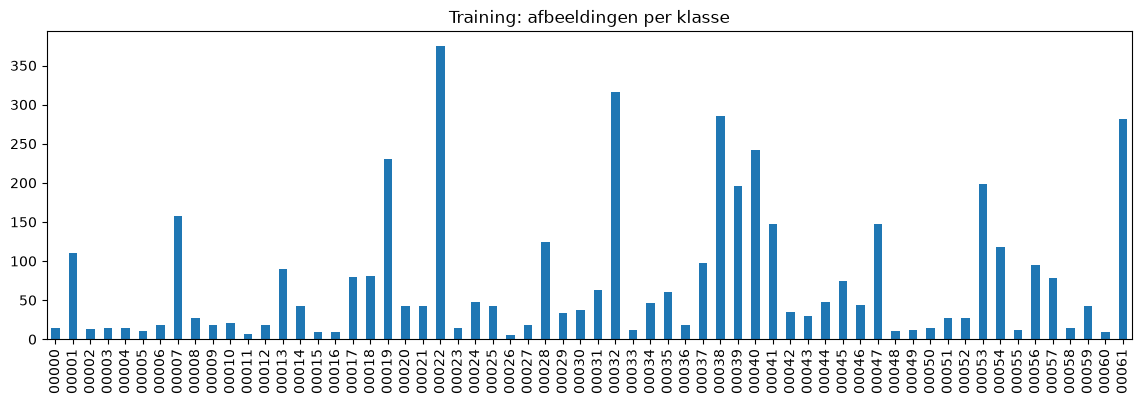

In [4]:
train_counts = {}

for class_dir in sorted(TRAIN_DIR.iterdir()):
    if not class_dir.is_dir():
        continue
    
    n_images = len(list(class_dir.glob("*.ppm")))
    train_counts[class_dir.name] = n_images

train_counts = pd.Series(train_counts)

print("Aantal klassen:", len(train_counts))
print("Totaal afbeeldingen:", train_counts.sum())
print("Kleinste klasse:", train_counts.idxmin(), train_counts.min())
print("Grootste klasse:", train_counts.idxmax(), train_counts.max())

train_counts.plot.bar(figsize=(14, 4), title="Training: afbeeldingen per klasse")
plt.show()

Aantal klassen: 62
Totaal afbeeldingen: 2520
Kleinste klasse: 00009 0
Grootste klasse: 00032 422


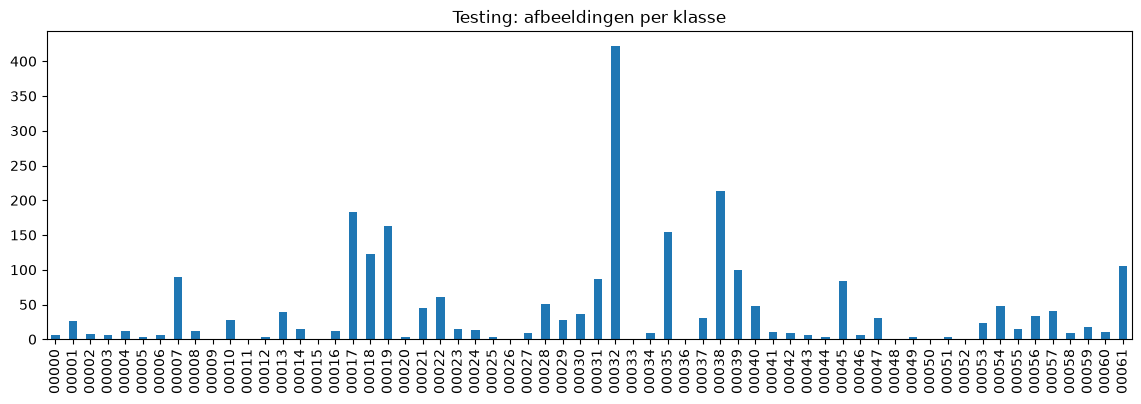

In [5]:
test_counts = {}

for class_dir in sorted(TEST_DIR.iterdir()):
    if not class_dir.is_dir():
        continue
    
    n_images = len(list(class_dir.glob("*.ppm")))
    test_counts[class_dir.name] = n_images

test_counts = pd.Series(test_counts)

print("Aantal klassen:", len(test_counts))
print("Totaal afbeeldingen:", test_counts.sum())
print("Kleinste klasse:", test_counts.idxmin(), test_counts.min())
print("Grootste klasse:", test_counts.idxmax(), test_counts.max())

test_counts.plot.bar(figsize=(14, 4), title="Testing: afbeeldingen per klasse")
plt.show()

          Filename  Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId
0  01153_00000.ppm    141     142      12      12     128     130        0
1  01153_00001.ppm    120     123      10      10     109     113        0
2  01153_00002.ppm    105     107       9       9      96      98        0
3  01160_00000.ppm     94     105       8       9      86      95        0
4  01160_00001.ppm    128     139      11      12     117     127        0
             Width       Height
count  4591.000000  4591.000000
mean    124.844261   109.740362
std      73.056649    60.209324
min      22.000000    20.000000
25%      79.000000    69.000000
50%     107.000000    96.000000
75%     151.000000   133.500000
max     724.000000   529.000000


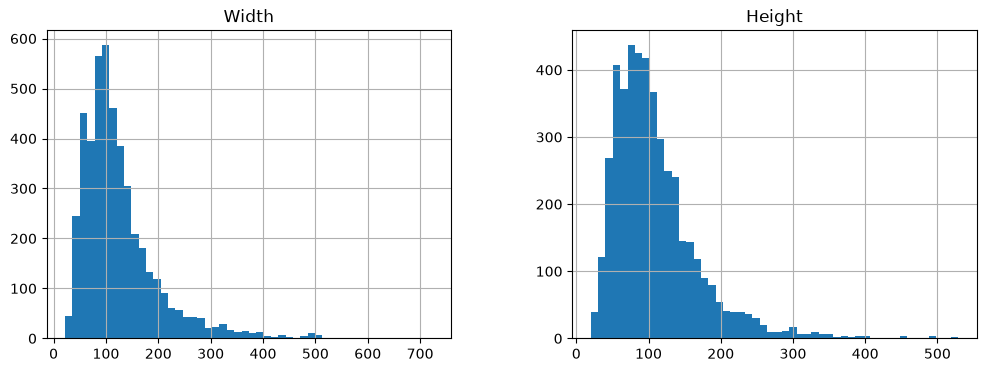

In [6]:
csv_frames = []

for class_dir in sorted(TRAIN_DIR.iterdir()):
    if not class_dir.is_dir():
        continue
    for csv_path in class_dir.glob("*.csv"):
        csv_frames.append(pd.read_csv(csv_path, sep=";"))

train_df = pd.concat(csv_frames, ignore_index=True)

print(train_df.head())
print(train_df[["Width", "Height"]].describe())

train_df[["Width", "Height"]].hist(bins=50, figsize=(12, 4))
plt.show()